# Human HARDI constant-solid-angle orientation reconstruction


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测 → 物理目标：hardi_csa_odf

**观测 y：** signal(1, 24, 24, 1, 160)；bvalues(1, 160)；directions(1, 160, 3)。具体单位以本Notebook数据表及README为准。

**恢复目标 x：** 逐体素45项ODF球谐系数。

**GT/参考来源：** **没有独立GT：以下仅为原方法参考重建，不能解释为物理真值。**

**由观测恢复目标：** 扩散信号为位移密度Fourier采样；ODF是径向积分。本地路径为 `solvers.reconstruct→fit_operator`。现有Notebook包含主动调用路径；本次只读审核未重跑，保留的execution_count/图像只说明已有输出，不能声称本轮执行。

**现有实验与图：** 保留图像输出位于cell 7（cell编号按文件内从0计）。章节包括：# Human HARDI constant-solid-angle orientation reconstruction；## 2. Data；## 3. Physics；## 4. Method；## 5. Results；## 6. Conclusion。应联合阅读观测图、完整恢复目标、参考差异与残差/敏感性实验；方法一致性不等于物理精度。

**限制：** 单壳只能得到CSA近似，无独立纤维取向GT。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem

Recover the water-displacement orientation distribution in each voxel of a human-brain diffusion MRI crop. A single measured angular shell provides incomplete radial information, while finite angular sampling and noise limit orientation detail. The requested even real spherical-harmonic expansion through degree eight contains 45 coefficients per voxel, in sr⁻¹, and can represent multiple orientations within a voxel rather than a single tensor axis. This review compares a fresh local reconstruction with an independently reproduced standard method; that numerical reference is **not anatomical ground truth**.


## 2. Data

Rokem et al.'s *High angular resolution diffusion MRI* (2013), Stanford Digital Repository, https://purl.stanford.edu/yx282xq2090 , supplies the acquired, motion-corrected magnitude images and gradient tables under PDDL 1.0. The original files `dwi.nii.gz`, `dwi.bvals` and `dwi.bvecs` were downloaded from https://stacks.stanford.edu/file/druid:yx282xq2090/ . From the original (81,106,76,160) image with 2 mm isotropic spacing, packaging selects zero-based `[40:64,40:64,35:36,:]` and retains all 160 volumes. Conversion to NPZ adds no interpolation, reorientation, intensity scaling or synthetic noise. These processed magnitudes are not scanner k-space; independent tissue truth is unavailable. DIPY supplies the reconstruction method rather than the observations. Complete attribution and license text are consolidated in `test/validation.md`.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| signal | (1, 24, 24, 1, 160) | float64 | MRI magnitude measurements in arbitrary instrument units; last axis is acquisition volume. |
| bvalues | (1, 160) | float64 | Diffusion weighting in s/mm^2, aligned to signal volumes. |
| directions | (1, 160, 3) | float64 | Dimensionless diffusion-gradient direction components, x/y/z in the supplied image coordinate convention; zero for unweighted volumes. |

### Acquisition metadata

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Sequence | Dual spin echo | dimensionless | Diffusion-weighted MRI acquisition |
| Weighted volumes | 150 | count | Single measured angular shell |
| Unweighted volumes | 10 | count | First ten acquisitions used to estimate S0 |
| Diffusion shell | 2000 | s/mm^2 | Nonzero diffusion weighting |
| b0 classification | 50 | s/mm^2 | Values at or below this cutoff are unweighted |
| Voxel spacing | 2, 2, 2 | mm | Image x, y, z spacing |
| Original crop | x=40:64, y=40:64, z=35:36 | voxel | Zero-based half-open indices in the deposited image |
| Gradient rounding | Maximum norm error 0.000007722 | dimensionless | Deposited text precision; compute angles from vector direction |
| Spatial boundary | Independent voxels | dimensionless | No spatial convolution or boundary extension |
| Motion correction | Rigid alignment to mean b0 | dimensionless | Depositor preprocessing |
| Eddy-current correction | Not applied by depositor | dimensionless | Dual-spin-echo acquisition |
| Noise variance | Not supplied | arbitrary units squared | No calibrated noise model is available |
| Timing and q magnitude | Not supplied | s and inverse mm | Single-shell CSA uses measured normalized angular attenuation, not full radial inversion |


In [1]:
from pathlib import Path
import os, sys, time, json, subprocess
import numpy as np
import matplotlib.pyplot as plt
root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
assert (root/'data/raw_data.npz').exists()
sys.path.insert(0, str(root))
from src.preprocessing import load_data
from src.solvers import reconstruct
from src.physics_model import sample_odf
from src.visualization import comparison, angular_comparison
data = load_data(root/'data/raw_data.npz')
{key:(value.shape,str(value.dtype)) for key,value in data.items()}

{'signal': ((1, 24, 24, 1, 160), 'float64'),
 'bvalues': ((1, 160), 'float64'),
 'directions': ((1, 160, 3), 'float64')}

## 3. Physics

For displacement vector $\mathbf r$ and diffusion wavevector $q\mathbf g$, the normalized magnitude signal approximates the displacement-density Fourier transform:

$$
E(q\mathbf g)=S(q\mathbf g)/S_0=\int P(\mathbf r)e^{-2\pi i q\mathbf g\cdot\mathbf r}d^3\mathbf r,
\qquad \Psi(\mathbf u)=\int_0^\infty P(r\mathbf u)r^2dr.
$$

$P$ is probability per displacement volume; $\Psi$ is orientation density per steradian, and $\mathbf g,\mathbf u$ are unit directions. Only the b = 2000 s/mm² shell is measured, so the full radial Fourier inversion is unavailable. CSA uses a single-shell radial approximation, not a calibrated axon-density model. Unknown diffusion timing prevents recovering an absolute radial displacement scale.

Image voxels are independent: the 2 mm spatial grid has no convolution boundary condition or spatial prior. The gradient vectors use the deposited image-coordinate convention. Polar angle is measured from +z; azimuth runs from +x toward +y. Their rounded lengths are removed when computing angles. Even SH degrees enforce antipodal symmetry. The 45 coefficients carry inverse-steradian scale and retain signs; there is no subsequent rotation, fitted scale or positivity projection.


## 4. Method

Normalize each voxel by mean b0 using the original float32 arithmetic; floor raw magnitude at 10⁻⁵, then clip weighted attenuation to [0.001,0.999]. Define y=log(-log(E)). For SH design B, degree l, spherical-Laplacian eigenvalues L=−l(l+1), and Legendre values F=P_l(0), solve min_a ‖Ba−y‖²+0.006‖diag(L)a‖² using the augmented design M = [B; sqrt(0.006) diag(L)] of shape (195,45). Its pseudoinverse M⁺ has shape (45,195); define H = M⁺[:,0:150], shape (45,150), so H acts directly on each 150-component transformed signal y. Then c=diag(FL/(8π))Hy, except c00=1/(2√π). Since B00=1/(2√π), the ODF integrates to one. Negative truncated-SH lobes remain possible and are not silently clipped.

The legacy real basis uses √2 Im Y(l,|m|) for m>0 and √2 Re Y(l,|m|) for m<0, with unchanged m=0. Degrees ascend 0,2,…,8 and orders ascend −l,…,l. Cartesian gradient components use the deposited image convention. The notebook executes the cleaned NumPy/SciPy implementation, with no upstream dependency.

The 150×45 angular design is augmented with 45 diagonal penalty rows. NumPy's SVD pseudoinverse directly solves this 195×45 least-squares system; each voxel uses the same 45×150 inverse. There is no initial iterate or convergence loop. All 576 voxel columns are transformed without a tissue mask. The following cell actively computes the complete bound reconstruction and submits it to the independent Judge. Its runtime is measured anew.


In [2]:
start = time.perf_counter()
fresh = reconstruct(data['signal'],data['bvalues'][0],data['directions'][0])
runtime = time.perf_counter()-start
(root/'output').mkdir(exist_ok=True)
np.savez_compressed(root/'output/reconstruction.npz', reconstruction=fresh)
# Historical review snapshots remain immutable; fresh submission is in output/.
print(f'Fresh local reconstruction: {runtime:.6f} s, {fresh.shape}, {fresh.dtype}')
command = [sys.executable,str(root/'evaluation/judge.py'),'--prediction',str(root/'output/reconstruction.npz'),'--report',str(root/'output/judge_report.json')]
completed = subprocess.run(command,capture_output=True,text=True)
assert completed.returncode == 0, completed.stderr
report = json.loads((root/'output/judge_report.json').read_text())
print(json.dumps(report,indent=2))

Fresh local reconstruction: 0.002876 s, (1, 24, 24, 1, 45), float64
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "relative_l2": 2.966295310539751e-15
  },
  "thresholds": {
    "relative_l2": {
      "comparison": "<=",
      "boundary": 1e-06
    }
  },
  "errors": []
}


## 5. Results

The saved code and outputs below belong to the existing notebook execution. This documentation review preserves those measurements and does not rerun reconstruction; “fresh” in the retained experiment narrative distinguishes the local run from the separately captured upstream result.

The independent DIPY 1.12.0 run used these exact observations; its stages and final coefficients were frozen before local extraction. The table compares that run with the newly computed local result using relative coefficient L2 error over all 25,920 entries, without alignment or scaling. Historical paper scores are not measurements of this crop.

The map panels show acquired mean unweighted magnitude, nonconstant coefficient norm and maximum original/local coefficient discrepancy. Three fixed-voxel angular sections compare complete xy-plane ODF curves. Polar plots display nonnegative radius for readability; stored coefficients, numerical comparisons and the Judge retain signed values. The following code prints the measured error, runtime and constant-mode checks.


Method | relative coefficient L2 error vs independent original
Independent original run | 0
Fresh local run | 2.966295310539751e-15


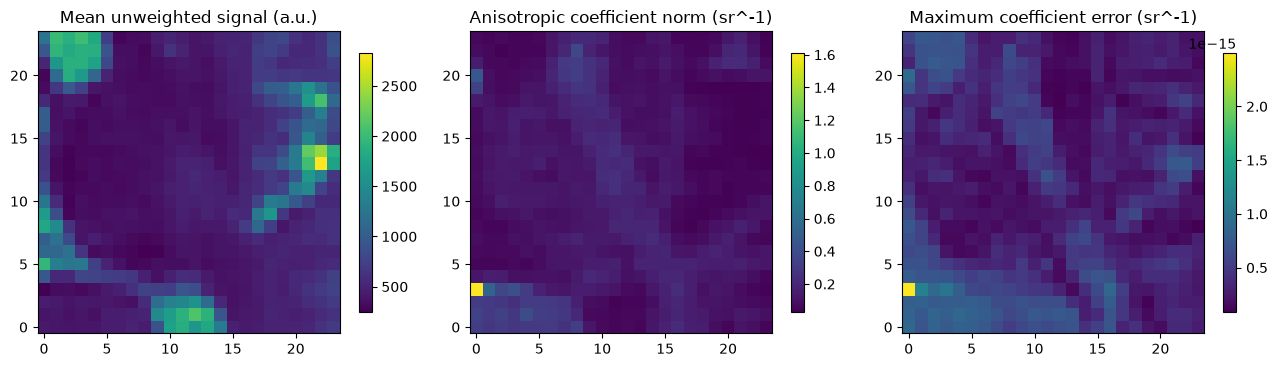

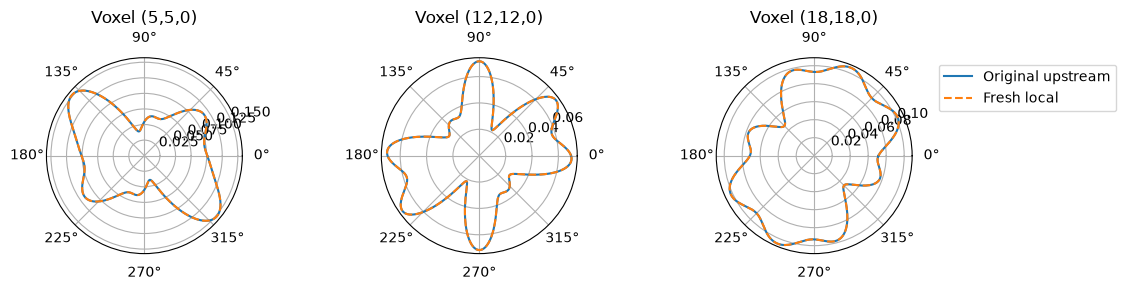

In [3]:
with np.load(root/'notebooks/reference_outputs/upstream.npz',allow_pickle=False) as reference:
    upstream = reference['reconstruction']
relative_l2 = float(np.linalg.norm(fresh-upstream)/np.linalg.norm(upstream))
maximum_error = float(np.max(abs(fresh-upstream)))
rows = [('Independent original run',0.0),('Fresh local run',relative_l2)]
print('Method | relative coefficient L2 error vs independent original')
for name,value in rows:
    print(f'{name} | {value:.17g}')
assert np.isclose(relative_l2,report['metrics']['relative_l2'],atol=1e-20)
fig = comparison(data['signal'],fresh,upstream)
plt.show()
fig = angular_comparison(fresh,upstream)
plt.show()

In [4]:
print({'fresh_runtime_seconds':runtime,'relative_l2':relative_l2,'maximum_coefficient_error':maximum_error,'minimum_fresh_constant_mode':float(fresh[...,0].min()),'maximum_fresh_constant_mode':float(fresh[...,0].max())})
assert fresh.shape == (1,24,24,1,45) and fresh.dtype == np.float64
assert np.isfinite(fresh).all()
assert report['passed']
print('Active reconstruction and standalone evaluation complete.')

{'fresh_runtime_seconds': 0.0028764999005943537, 'relative_l2': 2.966295310539751e-15, 'maximum_coefficient_error': 2.4980018054066022e-15, 'minimum_fresh_constant_mode': 0.28209479177387814, 'maximum_fresh_constant_mode': 0.28209479177387814}
Active reconstruction and standalone evaluation complete.


## 6. Conclusion

The fresh local CSA estimator reproduces the independent original: the measured all-coefficient relative L2 error is approximately 2.885 × 10⁻¹⁵, comfortably within the fixed 10⁻⁶ numerical boundary, and the angular curves overlap. Separate tests verify SH orthogonality, antipodal symmetry, unit integral for isotropic attenuation and the angular sampling adjoint, adding mathematical checks beyond implementation agreement.

This establishes reproduction of the selected single-shell approximation. Finite harmonic bandwidth, noise, the radial approximation and unavailable diffusion timing limit anatomical interpretation; individual ODF lobes do not independently prove axon geometry or calibrated fiber density.


The order-eight expansion contains 45 inverse-steradian coefficients per voxel and integrates to unit solid-angle density through its fixed constant coefficient. Negative truncated lobes are retained. Single-shell normalization and missing diffusion timing prevent interpreting this as a fully measured radial propagator or axon density.
